# Llevar una curva de PD a un año nuevo: PD escaladas, razón de verosimilitud escalada y QMM

**Pregunta:** Un sistema de calificación se calibró con 2009: ¿qué PD debe llevar cada uno de sus grados en 2010 y en 2011 una vez conocidos el perfil de calificaciones y la tasa de incumplimiento del año nuevo, y cuánto cuesta la elección del enfoque en peso de riesgo IRB?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema (una PD por grado y el promedio de largo plazo)
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este notebook puedes:

- decir qué es un modelo de calificación como distribución conjunta de grado e incumplimiento, y verificar las identidades de Tasche entre la curva de PD, el perfil de calificaciones y el perfil de incumplimientos en un modelo real;
- suavizar una curva de PD con el ajuste casi por momentos (QMM) y decir por qué una curva con ceros no se puede usar tal cual;
- llevar una curva de PD de un año de estimación a un año de pronóstico por los cuatro enfoques que conocen el perfil y la PD del pronóstico, cada uno con sus constantes impresas;
- decir qué agregan los casos en que solo se conoce la PD, o solo el perfil, y por qué llevar la curva vieja sin cambios es la elección más cara;
- leer la prueba chi cuadrado del perfil de incumplimientos implícito, y poner precio a la elección en peso de riesgo IRB.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.engines import pd_curve as pc
from riskvalidation.regulatory import irb

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Tres archivos versionados del caso C05, la calibración de una curva de PD sobre las calificaciones corporativas de S&P de Tasche (2013) (clase de licencia `derived-only`: el artefacto guarda el perfil de calificación, la tasa de incumplimiento por grado y los resultados, nunca los conteos por grado, así que ningún notebook recalcula nada que necesite los conteos; https://doi.org/10.21314/jcr.2013.169):

- `data/derived/C05/sp-2010.json` y `data/derived/C05/sp-2011.json`: el modelo de estimación de 2009 (`profile0`, `default_rate0`, `default_profile0`, `pd0`, `ar0`) y el perfil y la PD del año de pronóstico (`profile1`, `pd1`) sobre 17 grados de AAA a CCC-C, la curva que da cada enfoque (`approaches`), las pruebas versionadas (`tests`), las tablas impresas de Tasche junto al recálculo (`golden`) y el impacto en capital (`impact`).
- `data/derived/C05/models-sp2009.json`: las metas del suavizado de 2009 (`fit.targets`).

La pregunta es la que enfrenta un validador cada año. Un sistema de calificación se calibró con 2009: ¿qué PD debe llevar cada grado en 2010 y en 2011? El perfil de calificación del año nuevo se conoce, y su tasa de incumplimiento también.

La celda siguiente carga los archivos e imprime lo que contienen.

In [2]:
# Cargar los tres artefactos (el notebook está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
C05 = ROOT / "data" / "derived" / "C05"
load = lambda name: json.loads((C05 / name).read_text(encoding="utf-8"))
years = {2010: load("sp-2010.json"), 2011: load("sp-2011.json")}
fit2009 = load("models-sp2009.json")
o10 = years[2010]["outputs"]
grades = o10["grades"]

print("grados:", len(grades), grades[0], "...", grades[-1])
print("objetivos de 2009 del suavizado:", fit2009["fit"]["targets"])
for yr, doc in years.items():
    o = doc["outputs"]
    print(yr, "| deudores:", o["n_obligors"], "| incumplimientos:", o["n_defaults"],
          "| PD de pronóstico:", round(o["pd1"], 6), "| PD de 2009:", round(o["pd0"], 6))

grados: 17 AAA ... CCC-C
objetivos de 2009 del suavizado: {'pd': 0.0399317406, 'accuracy_ratio': 0.827102342}
2010 | deudores: 5522 | incumplimientos: 63 | PD de pronóstico: 0.011409 | PD de 2009: 0.039932
2011 | deudores: 5847 | incumplimientos: 44 | PD de pronóstico: 0.007525 | PD de 2009: 0.039932


## Método

### Paso 1: un modelo de calificación es una distribución conjunta

Tasche (2013) trata un modelo de calificación como la distribución conjunta del grado $X$ de un deudor al inicio de un período y su estado $D$ (incumplimiento) o $N$ (sobrevida) al final. Tres descripciones son equivalentes: el perfil de calificación $\Pr[X = x]$ con la curva de PD $\Pr[D \mid X = x]$; la PD incondicional $p$ con los dos perfiles condicionales $\Pr[X = x \mid D]$ y $\Pr[X = x \mid N]$; o $p$ con la razón de verosimilitud $\lambda(x) = \Pr[X = x \mid N] / \Pr[X = x \mid D]$. Las identidades entre ellas son

$$p = \sum_x \Pr[D \mid X = x]\,\Pr[X = x], \qquad \Pr[X = x \mid D] = \frac{\Pr[D \mid X = x]\,\Pr[X = x]}{p}, \qquad \Pr[D \mid X = x] = \frac{p}{p + (1 - p)\,\lambda(x)}$$

(ecuaciones 3.5a, 3.5b y 3.8 del artículo). La razón de precisión $\mathrm{AR}$ del sistema de calificación se calcula con los dos perfiles condicionales (ecuación 3.7).

La celda siguiente toma el modelo de 2009 del artefacto (el perfil de calificaciones y la tasa de incumplimiento de cada grado), deriva el perfil de incumplimientos, la PD incondicional y la razón de precisión con las funciones de `pd_curve` del motor, y los imprime junto a los valores que guarda el artefacto.

In [3]:
# El modelo de 2009: derivar los perfiles de supervivencia e incumplimiento, la PD y la razón de precisión
profile0 = np.array(o10["profile0"])
rate0 = np.array(o10["default_rate0"])
pd0, ar0 = o10["pd0"], o10["ar0"]
survival0 = pc.implied_survival_profile(rate0, profile0)
default0 = np.array(pc.implied_default_profile(rate0, profile0))
p_here = pc.unconditional_pd(rate0, profile0)
ar_here = pc.accuracy_ratio(default0, survival0)
lam0 = np.array(pc.likelihood_ratio(rate0[rate0 > 0], pd0))

print(f"{'':32s}{'derivado':>14s}{'en el artefacto':>20s}")
print(f"{'PD (3.5a)':32s}{100 * p_here:13.4f}%{100 * pd0:19.4f}%")
print(f"{'razón de precisión (3.7)':32s}{ar_here:14.4f}{ar0:20.4f}")
print("grados con tasa de incumplimiento cero:", int((rate0 == 0).sum()), "de", len(rate0),
      "| grados donde la razón de verosimilitud está definida:", lam0.size)

                                      derivado     en el artefacto
PD (3.5a)                              3.9932%             3.9932%
razón de precisión (3.7)                0.8271              0.8271
grados con tasa de incumplimiento cero: 6 de 17 | grados donde la razón de verosimilitud está definida: 11


La celda siguiente dibuja el perfil de calificaciones y el perfil de incumplimientos de 2009 por grado: dónde están los deudores y dónde cayeron los incumplimientos.

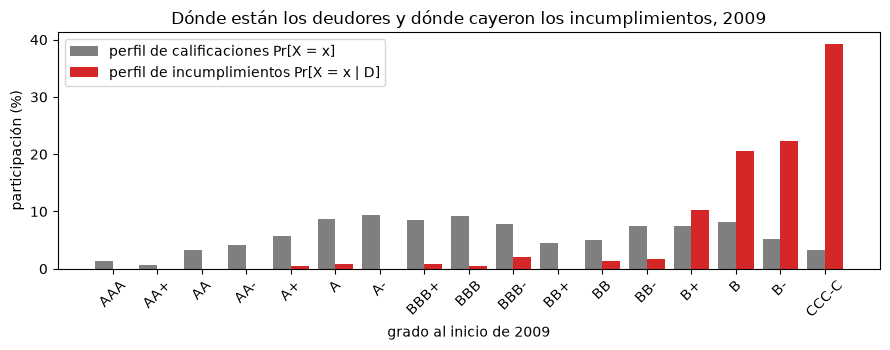

In [4]:
# Dibujar el perfil de calificaciones de 2009 y el perfil de incumplimientos derivado de la curva de PD
x = np.arange(len(grades))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(x - 0.2, 100 * profile0, 0.4, color="tab:gray", label="perfil de calificaciones Pr[X = x]")
ax.bar(x + 0.2, 100 * default0, 0.4, color="tab:red", label="perfil de incumplimientos Pr[X = x | D]")
ax.set_xticks(x)
ax.set_xticklabels(grades, rotation=45)
ax.set_xlabel("grado al inicio de 2009")
ax.set_ylabel("participación (%)")
ax.set_title("Dónde están los deudores y dónde cayeron los incumplimientos, 2009")
ax.legend()
fig.tight_layout()
plt.show()

El perfil de calificaciones se reparte en toda la escala, sin ningún grado sobre 9,3% de los deudores, mientras el perfil de incumplimientos se empuja hacia la derecha: B+, B, B- y CCC-C tienen el 92% de los incumplimientos y el 24% de los deudores. La distancia entre los dos conjuntos de barras es lo que resume la razón de precisión de 0,8271, y las dos descripciones están atadas por las identidades del paso, así que conocer el perfil y la curva de PD fija el perfil de incumplimientos. La figura no muestra la curva de PD misma, solo las dos distribuciones que conecta; con seis de las 17 tasas de incumplimiento crudas iguales a cero, la curva leída directamente de los conteos es el problema siguiente.

### Paso 2: suavizar la curva por ajuste casi por momentos

La tasa de incumplimiento cruda de 2009 es cero en seis de los 17 grados, así que una razón de verosimilitud construida con ella es cero o infinita ahí, y una PD de cero no sirve como curva. El ajuste cuasi de momentos (QMM, apéndice A de Tasche) ajusta la curva logística robusta

$$\Pr[D \mid X = x] = \frac{1}{1 + \exp\bigl(\alpha + \beta\,\Phi^{-1}(\tilde F_N(x))\bigr)}$$

con $\tilde F_N$ el promedio de la función de distribución de sobrevivientes y su versión continua por la izquierda (A.9), eligiendo $\alpha$ y $\beta$ para que la PD incondicional y la razón de precisión alcancen sus metas.

La celda siguiente llama a `qmm` con el perfil, la PD, la razón de precisión y el perfil de supervivencia de 2009 e imprime las constantes ajustadas.

In [5]:
# Ajustar la curva QMM a los objetivos de 2009 y verificar que los alcanza
q0 = pc.qmm(profile0, pd0, ar0, survival_profile=survival0)
curve0 = np.array(q0["pd_curve"])

print("alpha =", round(q0["alpha"], 4), "| beta =", round(q0["beta"], 4))
print("PD de la curva:", f"{100 * pc.unconditional_pd(curve0, profile0):.4f}%",
      "| razón de precisión de la curva:", round(pc.accuracy_ratio_from_curve(curve0, profile0), 4))
print("creciente con el grado:", bool(np.all(np.diff(curve0) > 0)))
for g in (0, grades.index("B")):
    print(grades[g], "| tasa cruda:", f"{100 * rate0[g]:.4f}%", "| curva QMM:", f"{100 * curve0[g]:.4f}%")

alpha = 5.2048 | beta = 2.1613
PD de la curva: 3.9932% | razón de precisión de la curva: 0.8271
creciente con el grado: True
AAA | tasa cruda: 0.0000% | curva QMM: 0.0028%
B | tasa cruda: 9.9585% | curva QMM: 7.9992%


La celda siguiente dibuja las tasas de incumplimiento crudas de 2009 y la curva suavizada en un eje logarítmico, con los seis grados de tasa cruda cero marcados al fondo.

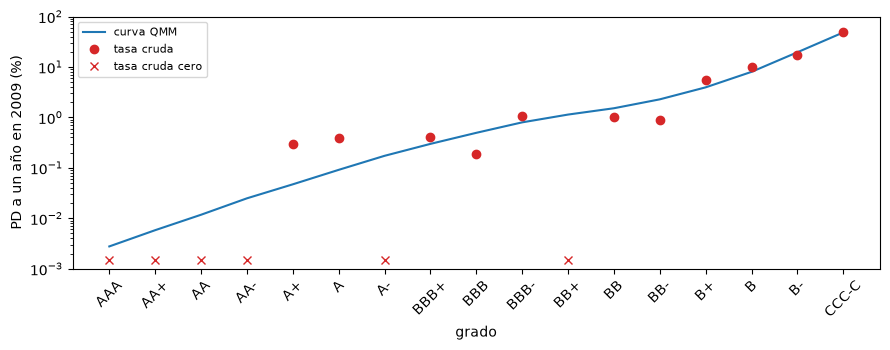

In [6]:
# Dibujar las tasas crudas (puntos) y la curva QMM (línea); las tasas cero quedan en el borde inferior
x = np.arange(len(grades))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(x, 100 * curve0, color="tab:blue", label="curva QMM")
ax.plot(x[rate0 > 0], 100 * rate0[rate0 > 0], "o", color="tab:red", label="tasa cruda")
ax.plot(x[rate0 == 0], np.full((rate0 == 0).sum(), 1.5e-3), "x", color="tab:red", label="tasa cruda cero")
ax.set_yscale("log")
ax.set_ylim(1e-3, 100)
ax.set_xticks(x)
ax.set_xticklabels(grades, rotation=45)
ax.set_xlabel("grado")
ax.set_ylabel("PD a un año en 2009 (%)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La curva es creciente con el grado, pasa por la PD de 2009 de 3,99% y la razón de precisión de 0,8271 por construcción, y da a AAA 0,0028% donde la tasa cruda es cero y a B 8,00% donde la tasa cruda es 9,96%. Los puntos crudos zigzaguean, un grado con unos cientos de deudores no puede resolver una tasa de una décima de punto porcentual, y los seis grados marcados al fondo tendrían una razón de verosimilitud de cero o infinito. La figura muestra el suavizado; no muestra que la curva sea correcta para 2010, ya que se ajustó a objetivos de 2009, y llevarla a un año nuevo es el tema del paso siguiente.

### Paso 3: llevar la curva cuando se conocen el perfil y la PD del año nuevo

Este es el caso 1 de Tasche: se conocen el perfil del pronóstico $\Pr_1[X = x]$ y la PD del pronóstico $p_1$, y la pregunta es qué parte del modelo queda como estaba. Cada enfoque es un supuesto sobre qué es invariante:

- **Perfil de incumplimiento invariante** (ecuación 4.2): $\Pr_1[X = x \mid D] = \Pr_0[X = x \mid D]$. Con $p_1$ y el perfil del pronóstico da un perfil de sobrevivientes crudo, luego una razón de precisión del pronóstico por (3.7), y QMM ajusta la curva a eso. Es propio solo si $p_1 \Pr_0[X=x\mid D] \le \Pr_1[X=x]$ en todo grado (4.6a).
- **Razón de precisión invariante** (4.3): $\mathrm{AR}_1 = \mathrm{AR}_0$, con QMM sobre el perfil y la PD del pronóstico.
- **PD escaladas** (4.4): $\Pr_1[D \mid X = x] = c_{PD}\,\Pr_0[D \mid X = x]$ con $c_{PD} = p_1 / \sum_x \Pr_0[D \mid X = x]\,\Pr_1[X = x]$ (4.7a). Simple y extendido, e impropio siempre que una PD escalada excede uno.
- **Razón de verosimilitud escalada** (4.5): $\lambda_1 = c_{LR}\,\lambda_0$, con $c_{LR}$ la raíz de $1 = \sum_x \Pr_1[X = x] / (p_1 + (1 - p_1)\,c_{LR}\,\lambda_0(x))$ (4.8a); la raíz existe y es única, así que el modelo es siempre propio.

La conclusión de Tasche es que escalar las PD es teóricamente cuestionable y que la razón de verosimilitud escalada y la razón de precisión invariante se comportan mucho mejor.

La celda siguiente corre los cuatro enfoques para 2010 y para 2011 e imprime, para 2010, las constantes de cada uno y la PD y la razón de precisión que da bajo el perfil de 2010.

In [7]:
# Los cuatro enfoques del caso 1 para ambos años de pronóstico, y las constantes de cada uno en 2010
curves = {}
for yr, doc in years.items():
    o = doc["outputs"]
    profile1, pd1 = np.array(o["profile1"]), o["pd1"]
    a1 = pc.invariant_default_profile(default0, profile1, pd1)
    a2 = pc.invariant_accuracy_ratio(profile1, pd1, ar0)
    a3 = pc.scaled_pds(curve0, profile1, pd1)
    a4 = pc.scaled_likelihood_ratio(curve0, q0["pd"], profile1, pd1)
    curves[yr] = {"A1-idp": a1["pd_curve"], "A2-iar": a2["pd_curve"],
                  "A3-spd": a3["pd_curve"], "A4-slr": a4["pd_curve"]}
    if yr == 2010:
        consts = (a1, a2, a3, a4)
profile1, pd1 = np.array(o10["profile1"]), o10["pd1"]
a1, a2, a3, a4 = consts

print("PD de pronóstico de 2010:", f"{100 * pd1:.2f}%", "| PD de 2009:", f"{100 * pd0:.2f}%")
print("A1: razón de precisión implícita", round(a1["accuracy_ratio_target"], 4))
print("A2: razón de precisión mantenida en el valor de 2009", round(ar0, 4))
print("A3: c_PD =", round(a3["c_pd"], 4), "| mayor PD escalada:", f"{100 * max(a3['pd_curve']):.1f}%")
print("A4: c_LR =", round(a4["c_lr"], 4), "| intervalo:", [round(v, 4) for v in a4["bracket"]])
print(f"{'enfoque':10s}{'PD bajo el perfil 2010':>34s}{'razón de precisión':>24s}")
for key, curve in curves[2010].items():
    implied = 100 * pc.unconditional_pd(curve, profile1)
    print(f"{key:10s}{implied:33.4f}%{pc.accuracy_ratio_from_curve(curve, profile1):24.4f}")

PD de pronóstico de 2010: 1.14% | PD de 2009: 3.99%
A1: razón de precisión implícita 0.7935
A2: razón de precisión mantenida en el valor de 2009 0.8271
A3: c_PD = 0.2642 | mayor PD escalada: 12.8%
A4: c_LR = 1.4081 | intervalo: [0.0188, 1.5494]
enfoque               PD bajo el perfil 2010      razón de precisión
A1-idp                               1.1409%                  0.7935
A2-iar                               1.1409%                  0.8271
A3-spd                               1.1409%                  0.8100
A4-slr                               1.1409%                  0.8451


La celda siguiente dibuja la curva de 2009 y las cuatro curvas para 2010 en un eje logarítmico.

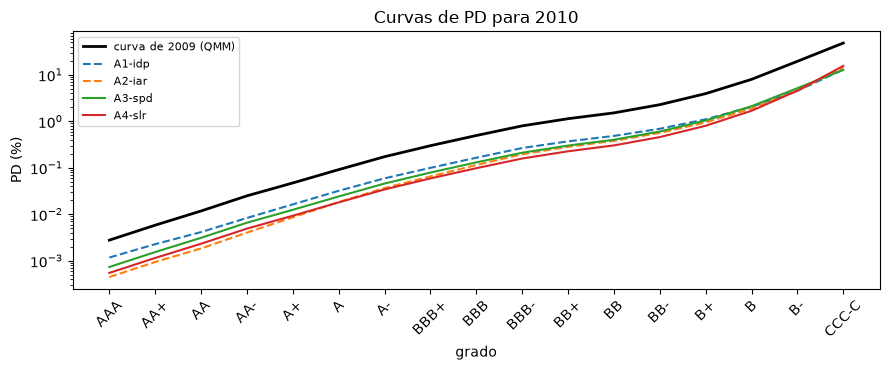

In [8]:
# Dibujar la curva de 2009 y las curvas de los cuatro enfoques para 2010
x = np.arange(len(grades))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(x, 100 * curve0, color="black", linewidth=2, label="curva de 2009 (QMM)")
for key, style in (("A1-idp", "--"), ("A2-iar", "--"), ("A3-spd", "-"), ("A4-slr", "-")):
    ax.plot(x, 100 * np.array(curves[2010][key]), style, label=key)
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(grades, rotation=45)
ax.set_xlabel("grado")
ax.set_ylabel("PD (%)")
ax.set_title("Curvas de PD para 2010")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Todos los enfoques reproducen la PD de pronóstico de 1,14% bajo el perfil de 2010, que es lo que el caso 1 les da para ajustar, y difieren en la forma. Las cuatro curvas quedan bajo la curva de 2009, porque 2010 fue un mejor año, pero no en la misma cantidad: escalar las PD multiplica todo grado por el mismo c_PD = 0,2642, mientras la razón de verosimilitud escalada, con c_LR = 1,4081, da a los mejores grados las PD más bajas de los cuatro y a CCC-C la más alta. Las razones de precisión que implican, 0,7935, 0,8271, 0,8100 y 0,8451, muestran que los enfoques discrepan en cuán bien separa el sistema a los deudores en 2010. La figura no puede decir cuál curva es correcta, solo dónde se separan los enfoques; los pasos siguientes prueban su forma y ponen precio a su diferencia.

### Paso 4: cuando se sabe menos

Dos casos más quitan información. En el **caso 2** solo se conoce la PD del pronóstico: la razón de verosimilitud invariante (ecuaciones 4.10 y 4.11, el cambio de tasa base de Elkan) conserva $\lambda_0$ y mueve solo la tasa base, $\Pr_1[D \mid X = x] = p_1 / (p_1 + (1 - p_1)\lambda_0(x))$. En el **caso 3** solo se conoce el perfil del pronóstico: la **curva de PD invariante** (4.12) conserva la curva de 2009 sin cambios y deja que la PD del pronóstico se siga de ella, $p_1 = \sum_x \Pr_0[D \mid X = x]\Pr_1[X = x]$ (4.13). Tasche advierte (sección 4.4.1) que esto lleva la PD incondicional del año de estimación al pronóstico.

La celda siguiente calcula ambos para 2010 e imprime la PD que cada uno implica bajo el perfil observado de 2010.

In [9]:
# Caso 2 (solo se conoce la PD) y caso 3 (se mantiene la curva de 2009) y la PD que implica cada uno en 2010
b1 = pc.invariant_likelihood_ratio(curve0, q0["pd"], pd_1=pd1)
c1 = pc.invariant_pd_curve(curve0, profile1)
implied_b1 = pc.unconditional_pd(b1["pd_curve"], profile1)

print("PD de pronóstico observada de 2010:", f"{100 * pd1:.2f}%")
print("B1: PD dada al enfoque", f"{100 * pd1:.2f}%",
      "| PD bajo el perfil observado:", f"{100 * implied_b1:.2f}%")
print("C1: PD que se sigue (4.13)", f"{100 * c1['pd']:.2f}%", "| PD de 2009:", f"{100 * pd0:.2f}%")
print("la curva de 2009 sin cambios frente a la PD observada, razón:", round(c1["pd"] / pd1, 2))

PD de pronóstico observada de 2010: 1.14%
B1: PD dada al enfoque 1.14% | PD bajo el perfil observado: 1.55%
C1: PD que se sigue (4.13) 4.32% | PD de 2009: 3.99%
la curva de 2009 sin cambios frente a la PD observada, razón: 3.78


El caso 2 muestra para qué sirve el perfil. Si solo se le dice la PD, la razón de verosimilitud invariante da 1,55% bajo el perfil observado de 2010 en lugar del 1,14% que se le dio: sin el perfil no puede ser consistente con él. El caso 3 muestra el costo de no hacer nada: la curva de 2009, aplicada al perfil de 2010, pronostica una PD de 4,32% frente a un 1,14% observado, 3,8 veces más. Un validador que encuentra la misma curva en uso un año después, y un perfil que ha mejorado, está mirando una calibración que sobrestima la PD en ese factor, y el paso siguiente le pone precio.

### Paso 5: probar la forma del perfil de incumplimiento implicado

Una curva calibrada implica dónde caen los incumplimientos en los grados: el perfil de incumplimiento implicado $q_x = n_x\,\mathrm{PD}_x / \sum_t n_t\,\mathrm{PD}_t$ (ecuación 3.5b). La prueba registrada del motor `pd.default_profile` compara los conteos de incumplimientos observados con él con el chi-cuadrado de Pearson, $T = \sum_x (d_x - D q_x)^2 / (D q_x)$ con $D$ el número de incumplimientos, y, como los conteos esperados son pequeños en los grados buenos, toma el valor p de 100.000 muestras multinomiales (semilla 2013). Ve la forma de la curva y no su nivel. La prueba necesita los conteos por grado, que la fuente no permite publicar, así que esta celda lee las filas versionadas (9 enfoques, dos años) y no las recalcula.

In [10]:
# Leer las pruebas versionadas del perfil de incumplimientos de los nueve enfoques en 2010 y 2011
tests = {}
for yr, doc in years.items():
    tests[yr] = {t["model_id"]: t for t in doc["tests"] if t["test_id"] == "pd.default_profile"}
keys = list(tests[2010])
print("calculado con riskvalidation", years[2010]["provenance"]["riskvalidation_version"],
      "| instalado", md.version("riskvalidation"))

print(f"{'enfoque':10s}{'T 2010':>9s}{'p 2010':>9s}{'luz':>8s}{'T 2011':>9s}{'p 2011':>9s}{'luz':>8s}")
for key in keys:
    a, b = tests[2010][key], tests[2011][key]
    print(f"{key:10s}{a['statistic']:9.2f}{a['p_value']:9.4f}{a['light']:>8s}",
          f"{b['statistic']:9.2f}{b['p_value']:9.4f}{b['light']:>8s}")

calculado con riskvalidation 1.0.1 | instalado 1.0.1
enfoque      T 2010   p 2010     luz   T 2011   p 2011     luz
A1-idp        31.40   0.0458   amber      6.32   0.7817   green
A2-iar        24.42   0.0791   green      4.51   0.8910   green
A3-spd        33.70   0.0425   amber     11.79   0.3696   green
A4-slr        21.47   0.1115   green      5.55   0.8199   green
B1-ilr        22.67   0.1011   green      5.71   0.8076   green
C1-ipc        33.70   0.0425   amber     11.79   0.3696   green
C2-ls         36.87   0.0335   amber     10.77   0.4215   green
C3-chi2       39.02   0.0293   amber      9.44   0.5095   green
C4-ilr        39.14   0.0291   amber      9.36   0.5153   green


La celda siguiente dibuja el valor p de la prueba del perfil de incumplimientos para cada uno de los nueve enfoques en ambos años, con la línea de 5%.

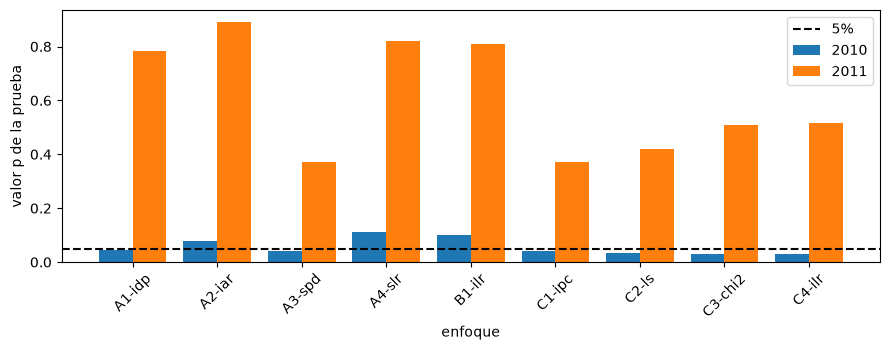

In [11]:
# Dibujar el valor p de la prueba del perfil de incumplimientos de cada enfoque, ambos años
x = np.arange(len(keys))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(x - 0.2, [tests[2010][k]["p_value"] for k in keys], 0.4, color="tab:blue", label="2010")
ax.bar(x + 0.2, [tests[2011][k]["p_value"] for k in keys], 0.4, color="tab:orange", label="2011")
ax.axhline(0.05, color="black", linestyle="--", label="5%")
ax.set_xticks(x)
ax.set_xticklabels(keys, rotation=45)
ax.set_xlabel("enfoque")
ax.set_ylabel("valor p de la prueba")
ax.legend()
fig.tight_layout()
plt.show()

En 2010 la prueba de forma separa a los enfoques: el perfil de incumplimientos invariante (p = 0,0458) y las PD escaladas (p = 0,0425) caen bajo 5% y son ámbar, mientras la razón de verosimilitud escalada (p = 0,1115) y la razón de precisión invariante (p = 0,0791) siguen verdes, y los casos que llevan la curva de 2009 o su razón de verosimilitud también son ámbar. En 2011 los nueve enfoques son verdes, con p de 0,37 a 0,89. Los valores p vienen de 100.000 sorteos multinomiales con un error de Monte Carlo de unos 0,0007. La prueba ve la forma de la curva y no su nivel, así que no puede distinguir una curva demasiado alta en todas partes de una buena; el peso de riesgo del paso siguiente lleva el nivel.

### Paso 6: el precio de la elección en ponderador de riesgo IRB

Una curva de PD es un insumo del capital. El artefacto versiona, para cada enfoque, el ponderador de riesgo IRB medio de la cartera del pronóstico, una unidad de exposición por deudor, con la función corporativa de Basilea III, una LGD de 45% (F-IRB sin garantía preferente, instituciones financieras, CRE32.6), un vencimiento de 2,5 años y el piso de PD de 0,05% (CRE32.4); https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27.

La celda siguiente lo recalcula con el `capital_requirement` del motor para las seis curvas de este notebook en ambos años, e imprime cuánto más capital pide la curva de 2009 sin cambios que la razón de verosimilitud escalada.

In [12]:
# Peso de riesgo IRB promedio de cada portafolio de pronóstico bajo las seis curvas, ambos años
cfg = o10["irb"]
weights = {}
for yr, doc in years.items():
    o = doc["outputs"]
    prof, p1 = np.array(o["profile1"]), o["pd1"]
    six = dict(curves[yr])
    six["B1-ilr"] = pc.invariant_likelihood_ratio(curve0, q0["pd"], pd_1=p1)["pd_curve"]
    six["C1-ipc"] = pc.invariant_pd_curve(curve0, prof)["pd_curve"]
    required = {}
    for key, curve in six.items():
        required[key] = [irb.capital_requirement(cfg["asset_class"], float(p), cfg["lgd"], maturity=cfg["maturity"],
                                                 regime=cfg["regime"]).risk_weight for p in curve]
    weights[yr] = {k: float(np.sum(prof * np.array(v))) for k, v in required.items()}

print(f"{'enfoque':10s}{'peso de riesgo 2010':>26s}{'peso de riesgo 2011':>26s}")
for key in weights[2010]:
    print(f"{key:10s}{100 * weights[2010][key]:25.1f}%{100 * weights[2011][key]:25.1f}%")
for yr in years:
    stale = weights[yr]["C1-ipc"] / weights[yr]["A4-slr"] - 1.0
    case1 = [weights[yr][k] for k in ("A1-idp", "A2-iar", "A3-spd", "A4-slr")]
    spread = max(case1) / min(case1) - 1.0
    print(yr, "| la curva de 2009 sin cambios cuesta más:", f"{100 * stale:.1f}%",
          "| dispersión de los enfoques del caso 1:", f"{100 * spread:.1f}%")

enfoque          peso de riesgo 2010       peso de riesgo 2011
A1-idp                         60.9%                     51.6%
A2-iar                         57.3%                     49.4%
A3-spd                         58.8%                     53.5%
A4-slr                         55.0%                     50.5%
B1-ilr                         61.6%                     53.3%
C1-ipc                         90.7%                     92.6%
2010 | la curva de 2009 sin cambios cuesta más: 64.8% | dispersión de los enfoques del caso 1: 10.7%
2011 | la curva de 2009 sin cambios cuesta más: 83.3% | dispersión de los enfoques del caso 1: 8.3%


La celda siguiente dibuja el peso de riesgo que cada enfoque da a los portafolios de 2010 y 2011.

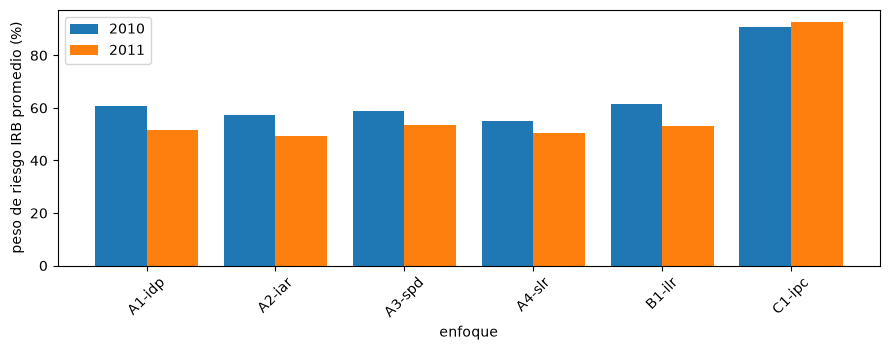

In [13]:
# Dibujar el peso de riesgo IRB promedio por enfoque, ambos años
names = list(weights[2010])
x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(x - 0.2, [100 * weights[2010][k] for k in names], 0.4, color="tab:blue", label="2010")
ax.bar(x + 0.2, [100 * weights[2011][k] for k in names], 0.4, color="tab:orange", label="2011")
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=45)
ax.set_xlabel("enfoque")
ax.set_ylabel("peso de riesgo IRB promedio (%)")
ax.legend()
fig.tight_layout()
plt.show()

Los cuatro enfoques que conocen el perfil y la PD nuevos fijan el precio del portafolio de 2010 entre 55,0% y 60,9% de peso de riesgo, una dispersión de 10,7%, y de 8,3% en 2011; la elección entre ellos vale unos puntos de capital. Llevar la curva de 2009 sin cambios es de otro orden de costo, 90,7% en 2010 y 92,6% en 2011, que es 64,8% y 83,3% más capital que la razón de verosimilitud escalada. La figura muestra la asimetría: el validador que pregunta si se actualizó una calibración pregunta por el mayor ítem de la tabla, y el que pregunta cuál actualización se usó, por el menor.

### Paso 7: frente a las tablas impresas de Tasche

Tasche imprime la curva suavizada de 2009 en porcentaje (Tabla 5, con tres decimales), las curvas de pronóstico de los cuatro enfoques del caso 1 con los valores p de la prueba del perfil de incumplimiento (Tabla 7, cuatro decimales para las curvas) y las PD de pronóstico del caso 3 (Tabla 8). El artefacto versiona cada celda impresa junto al recálculo (`golden`).

La celda siguiente compara la Tabla 5 impresa con la curva QMM del Paso 2 y las curvas impresas de la Tabla 7 con las curvas del Paso 3 en puntos porcentuales, y luego lee los valores p y las PD del caso 3 versionados.

In [14]:
# Las Tablas 5 y 7 impresas de Tasche frente a estas curvas, y luego los valores p y PD versionados
golden = o10["golden"]
printed5 = np.array([row["printed"] for row in golden["table5"]])
gap5 = float(np.abs(100 * curve0 - printed5).max())
print("Tabla 5, mayor brecha en puntos:", round(gap5, 4))
for key in ("A1-idp", "A2-iar", "A3-spd", "A4-slr"):
    printed = np.array([row["printed"] for row in golden["table7"][key]])
    gap = float(np.abs(100 * np.array(curves[2010][key]) - printed).max())
    print(f"Tabla 7 {key}: {printed.size} celdas, mayor brecha en puntos {gap:.4f}")
print(f"{'enfoque':10s}{'p impreso (%)':>22s}{'versionado (%)':>22s}")
for row in golden["table7_p_values"]:
    print(f"{row['approach']:10s}{row['printed_pct']:22.2f}{row['ours_pct']:22.2f}")
for row in golden["table8"]:
    print(row["approach"], "| PD impresa", row["printed_pct"], "% | versionado", row["ours_pct"], "%")

Tabla 5, mayor brecha en puntos: 0.0013
Tabla 7 A1-idp: 17 celdas, mayor brecha en puntos 0.0001
Tabla 7 A2-iar: 17 celdas, mayor brecha en puntos 0.0002
Tabla 7 A3-spd: 17 celdas, mayor brecha en puntos 0.0003
Tabla 7 A4-slr: 17 celdas, mayor brecha en puntos 0.0005
enfoque            p impreso (%)        versionado (%)
A1-idp                      4.60                  4.58
A2-iar                      8.00                  7.91
A3-spd                      4.00                  4.25
A4-slr                     11.30                 11.15
C1-ipc | PD impresa 4.32 % | versionado 4.318 %
C2-ls | PD impresa 4.8 % | versionado 4.799 %
C3-chi2 | PD impresa 5.35 % | versionado 5.347 %
C4-ilr | PD impresa 5.38 % | versionado 5.377 %


## Resultados

**Respuesta:** lleva la curva de 2009 con un enfoque que use el perfil y la PD del año nuevo, nunca sin cambios. La PD de pronóstico de 2010 es 1,14%, frente a 3,99% en 2009; la curva de 2009 sin cambios pronostica 4,32% bajo el perfil de 2010, 3,8 veces la PD observada, y da al portafolio de 2010 un peso de riesgo IRB promedio de 90,7% frente a 55,0% con la razón de verosimilitud escalada: 64,8% más capital en 2010 y 83,3% en 2011. Los cuatro enfoques que conocen el perfil y la PD nuevos difieren en 10,7% de peso de riesgo en 2010 (55,0% razón de verosimilitud escalada, 57,3% razón de precisión invariante, 58,8% PD escaladas, 60,9% perfil de incumplimientos invariante), y la prueba de forma se pone del lado de los dos primeros (p = 0,1115 y 0,0791) frente a los dos últimos (p = 0,0458 y 0,0425).

- **El modelo de 2009 es una distribución conjunta consistente.** El motor deriva la PD incondicional (3,9932%) y la razón de precisión (0,8271) desde el perfil y las tasas de incumplimiento por grado. Seis de las 17 tasas crudas son cero, así que una razón de verosimilitud construida sobre ellas no está definida y la curva debe suavizarse.
- **QMM.** Con alfa = 5,2048 y beta = 2,1613 la curva suavizada alcanza los objetivos de 2009. Da a AAA 0,0028% donde la tasa cruda es 0, a B 7,9992% donde la tasa cruda es 9,9585%, y es creciente con el grado.
- **Caso 1, 2010.** Escalar las PD multiplica todo grado por c_PD = 0,2642; la razón de verosimilitud escalada tiene c_LR = 1,4081. Las razones de precisión de los cuatro enfoques son 0,7935 (perfil de incumplimientos invariante), 0,8271 (mantenida de 2009), 0,8100 (PD escaladas) y 0,8451 (razón de verosimilitud escalada).
- **Cuando se sabe menos.** Con solo la PD (caso 2), la razón de verosimilitud invariante da 1,55% bajo el perfil observado de 2010 en lugar del 1,14% que se le dio.
- **Frente a lo impreso.** Las cuatro curvas de la Tabla 7 quedan a menos de 0,0005 puntos porcentuales de los valores impresos de Tasche en todo grado, y la mayor brecha de la Tabla 5 es 0,0013 puntos.

Lo que este notebook no muestra: la comparación de los nueve enfoques sobre el pronóstico frente a la PD observada (notebook 09), ni cómo un error de calibración se propaga por la fórmula IRB (notebook 07).

## Resumen

- Un modelo de calificación es una distribución conjunta de grado e incumplimiento; la curva de PD, los dos perfiles condicionales y la razón de verosimilitud son descripciones equivalentes y el motor deriva una de otra.
- Una curva con tasas cero se suaviza con QMM antes de llevarla a un año nuevo.
- Con el perfil y la PD de pronóstico conocidos, cuatro enfoques llevan la curva; difieren en lo que mantienen invariante y sus curvas difieren en forma, no en la PD de pronóstico. Escalar las PD es lo más simple y lo menos defendible.
- Mantener la curva vieja sin cambios pronostica una PD 3,8 veces la observada y cuesta 65% a 83% más capital que la razón de verosimilitud escalada.
- La prueba del perfil de incumplimientos ve la forma de una curva, no su nivel; las tablas impresas de Tasche son la verificación del recálculo.

**Qué probar después.** Reemplaza la PD de pronóstico del Paso 3 por la PD de 2009 y mira qué enfoques mantienen la curva y cuáles la mueven; luego lee el notebook 06.

## Referencias

- Tasche, D. (2013), The art of probability-of-default curve calibration, Journal of Credit Risk 9(4), 63-103, ecuaciones 3.5, 3.7, 3.8, 4.2 a 4.15 y apéndice A, Tablas 6 a 8; arXiv 1212.3716. https://doi.org/10.21314/jcr.2013.169
- BCBS, Basel Framework, CRE32, enfoque IRB: cálculo de activos ponderados por riesgo (LGD, vencimiento y piso de PD). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- Elkan, C. (2001), The foundations of cost-sensitive learning, IJCAI, para el cambio de tasa base (ecuación 4.11).
- Pearson, K. (1900), On the criterion that a given system of deviations from the probable in the case of a correlated system of variables is such that it can be reasonably supposed to have arisen from random sampling, Philosophical Magazine 50(302), 157-175.